<a href="https://colab.research.google.com/github/prangunj23/CS163-Radio-Interferometry-Project/blob/main/Aman_Viz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pyuvdata
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 11.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pyuvdata]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
from collections import defaultdict
folder_path = '/content/drive/MyDrive/CS 163/cs163_data/'
filetypes = defaultdict(int)
uv_files, cal_files = [], []
for filename in os.listdir(folder_path):
    if filename.endswith('.uvfits'):
        uv_files.append(os.path.join(folder_path, filename))
    elif filename.endswith('.calfits'):
        cal_files.append(os.path.join(folder_path, filename))

    filetypes[filename.split('.')[-1]] += 1

filetypes

defaultdict(int, {'calfits': 10000, 'uvfits': 10000})

In [ ]:
uv_files[0]

'/content/drive/MyDrive/CS 163/cs163_data/uncalib_data_9500.uvfits'

In [ ]:
cal_files[0]

'/content/drive/MyDrive/CS 163/cs163_data/gains_9500.calfits'

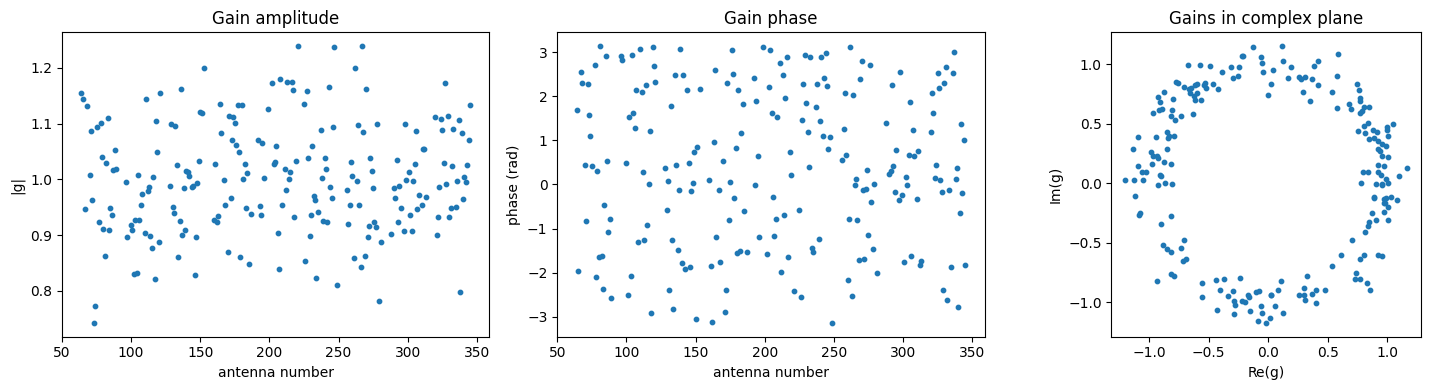

In [ ]:
from pyuvdata import UVCal
import matplotlib.pyplot as plt
import numpy as np

uvc = UVCal.from_file(folder_path + 'gains_0.calfits')

g = uvc.gain_array.squeeze()   # 214 complex numbers, one per antenna
ants = uvc.ant_array

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(ants, np.abs(g), s=10)
ax[0].set(title='Gain amplitude', xlabel='antenna number', ylabel='|g|')

ax[1].scatter(ants, np.angle(g), s=10)
ax[1].set(title='Gain phase', xlabel='antenna number', ylabel='phase (rad)')

ax[2].scatter(g.real, g.imag, s=10)
ax[2].set(title='Gains in complex plane', xlabel='Re(g)', ylabel='Im(g)', aspect='equal')

plt.tight_layout()
plt.show()

In [ ]:
import re

def file_idx(f):
    return int(re.findall(r'\d+', os.path.basename(f))[-1])  # last number in the filename

cal_by_idx = {file_idx(f): f for f in cal_files}
uv_by_idx  = {file_idx(f): f for f in uv_files}

common = sorted(cal_by_idx.keys() & uv_by_idx.keys())
pairs = [(cal_by_idx[i], uv_by_idx[i]) for i in common]

Antenna layout

antennas in telescope: 352 | in data: 214


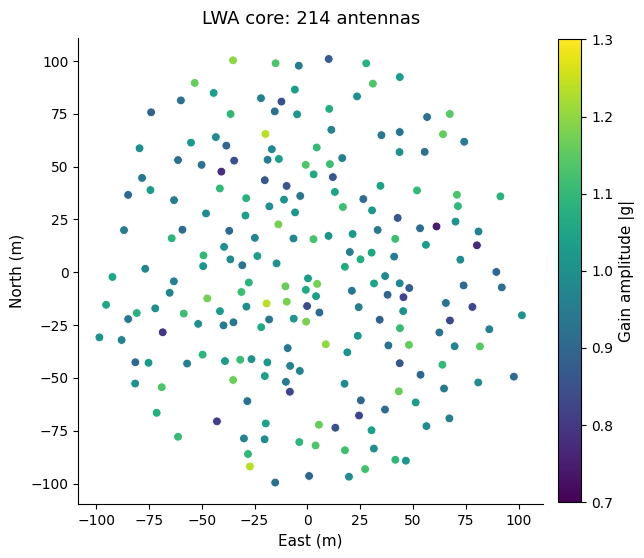

In [ ]:
from pyuvdata import UVData, UVCal

cal_f, uv_f = pairs[0]
uvc = UVCal.from_file(cal_f)
uvd = UVData.from_file(uv_f)

out = uvd.telescope.get_enu_antpos()
enu = out[0] if isinstance(out, tuple) else out
nums = uvd.telescope.antenna_numbers

in_data = np.isin(nums, uvd.get_ants())
print("antennas in telescope:", len(nums), "| in data:", in_data.sum())

amp = dict(zip(uvc.ant_array, np.abs(uvc.gain_array.squeeze())))
colors = [amp.get(a, np.nan) for a in nums[in_data]]

fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(enu[in_data, 0], enu[in_data, 1], c=colors, cmap='viridis',
                s=40, edgecolors='white', linewidths=0.6, vmin=0.7, vmax=1.3)
cb = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
cb.set_label('Gain amplitude |g|', fontsize=11)

ax.set_aspect('equal')
ax.set_xlabel('East (m)', fontsize=11)
ax.set_ylabel('North (m)', fontsize=11)
ax.set_title('LWA core: 214 antennas', fontsize=13, pad=10)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig('antenna_layout.png', dpi=300, bbox_inches='tight')
plt.show()

u-v coverage

In [ ]:
# observing frequency in Hz
freq = uvd.freq_array.ravel()[0]
# wavelength = speed of light / frequency
lam = 299792458 / freq
print(f"freq = {freq/1e6:.1f} MHz, wavelength = {lam:.2f} m")

freq = 47.3 MHz, wavelength = 6.33 m


In [ ]:
cross = uvd.ant_1_array != uvd.ant_2_array    # True for real pairs, False for autos
u = uvd.uvw_array[cross, 0] / lam             # column 0 = u, converted to wavelengths
v = uvd.uvw_array[cross, 1] / lam             # column 1 = v
print(len(u), "baselines")                    # expect 22,791

22791 baselines


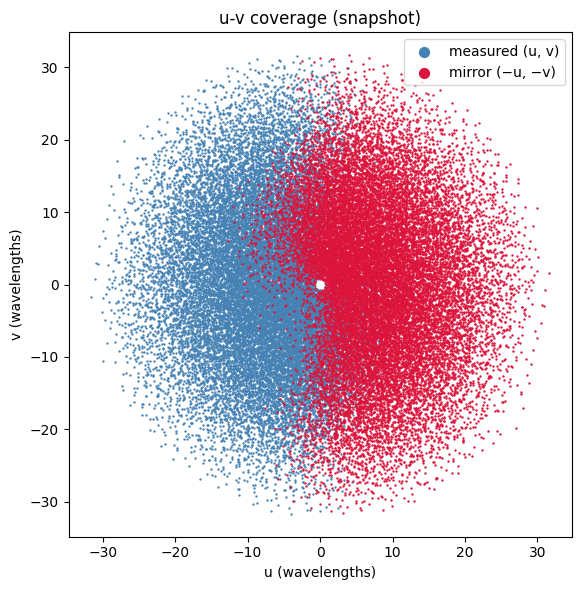

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(u, v, s=0.5, c='steelblue', label='measured (u, v)')
ax.scatter(-u, -v, s=0.5, c='crimson', label='mirror (−u, −v)')
ax.set(xlabel='u (wavelengths)', ylabel='v (wavelengths)',
       title='u-v coverage (snapshot)', aspect='equal')
ax.legend(markerscale=10)
plt.tight_layout()
plt.savefig('uv_coverage.png', dpi=300)
plt.show()

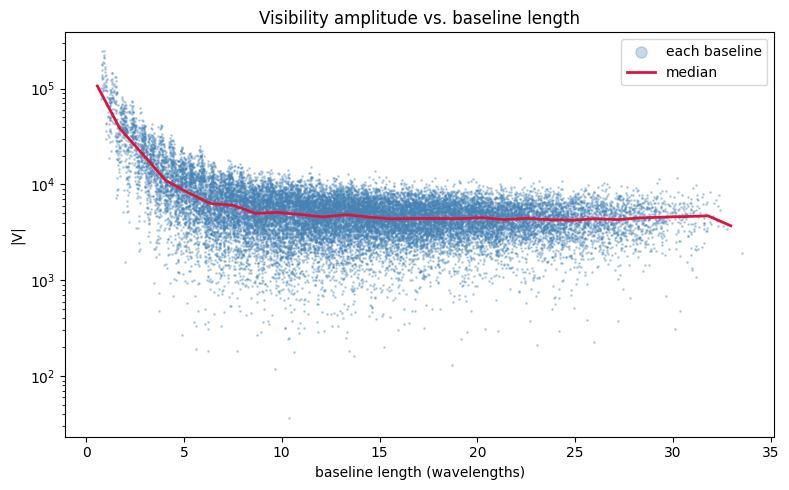

In [ ]:
vis_cross = uvd.data_array.ravel()[cross]
amp = np.abs(vis_cross)
# baseline length in wavelengths
r = np.sqrt(u**2 + v**2)

bins = np.linspace(0, r.max(), 30)
centers = 0.5 * (bins[1:] + bins[:-1])
med = [np.median(amp[(r >= lo) & (r < hi)]) for lo, hi in zip(bins[:-1], bins[1:])]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(r, amp, s=1, alpha=0.3, c='steelblue', label='each baseline')
ax.plot(centers, med, c='crimson', lw=2, label='median')
ax.set(xlabel='baseline length (wavelengths)', ylabel='|V|',
       title='Visibility amplitude vs. baseline length', yscale='log')
ax.legend(markerscale=8)
plt.tight_layout()
plt.savefig('amp_vs_baseline.png', dpi=300)
plt.show()

In [ ]:
uvd.ant_1_array[:100]

array([64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64,
       64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64,
       64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64,
       64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64,
       64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64,
       64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64],
      dtype=int32)

In [ ]:
uvd.ant_2_array[:100]

array([ 64,  65,  67,  68,  70,  71,  72,  73,  74,  75,  77,  78,  79,
        80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  96,  97, 100,
       101, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 114,
       115, 116, 117, 118, 119, 120, 121, 128, 129, 130, 131, 132, 133,
       134, 135, 136, 137, 138, 139, 140, 141, 142, 144, 145, 146, 147,
       148, 149, 150, 151, 153, 160, 161, 162, 163, 164, 165, 167, 168,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182,
       183, 184, 185, 187, 192, 193, 194, 195, 196], dtype=int32)

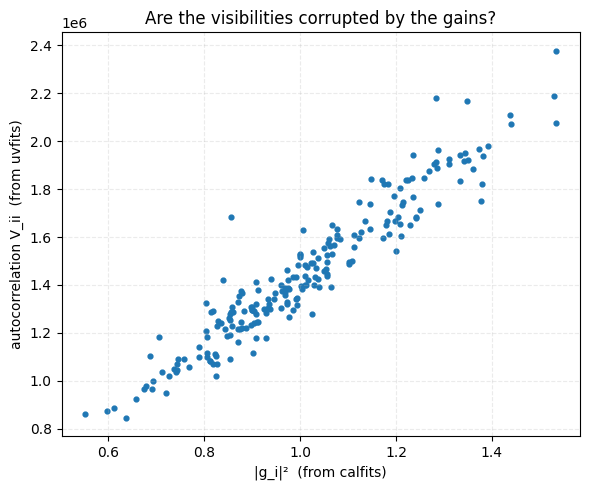

In [ ]:
autos = uvd.ant_1_array == uvd.ant_2_array
auto_ants = uvd.ant_1_array[autos]
auto_vals = np.abs(uvd.data_array.ravel()[autos])

g_amp = dict(zip(uvc.ant_array, np.abs(uvc.gain_array.squeeze())))
g2 = np.array([g_amp[a]**2 for a in auto_ants])

plt.figure(figsize=(6, 5))
plt.scatter(g2, auto_vals, s=12)
plt.xlabel('|g_i|²  (from calfits)'); plt.ylabel('autocorrelation V_ii  (from uvfits)')
plt.title('Are the visibilities corrupted by the gains?')
plt.grid(alpha=0.25, linestyle='--'); plt.tight_layout()
plt.savefig('autos_vs_gains.png', dpi=300); plt.show()

gain_convention: divide


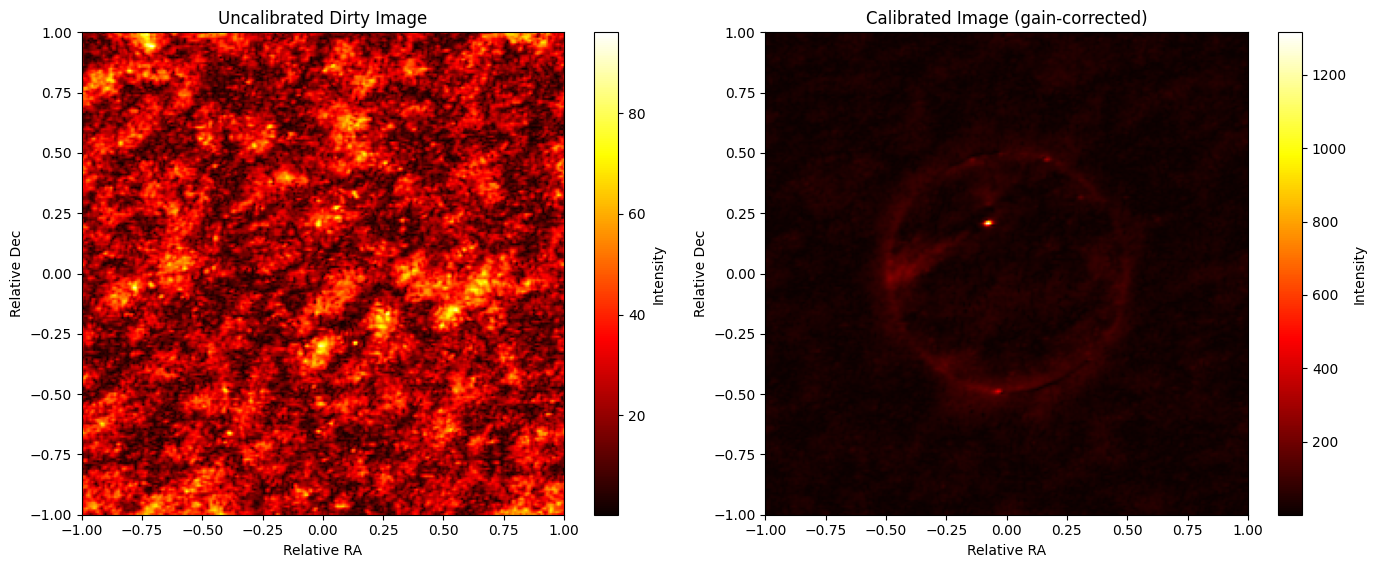

In [ ]:
def uncalibraed_image(u, v, vis, grid_size=256):
    max_uv = max(np.max(np.abs(u)), np.max(np.abs(v)))
    uv_grid = np.zeros((grid_size, grid_size), dtype=complex)
    bins = np.linspace(-max_uv, max_uv, grid_size)
    ui = np.clip(np.digitize(u, bins) - 1, 0, grid_size - 1)
    vi = np.clip(np.digitize(v, bins) - 1, 0, grid_size - 1)
    for a, b, val in zip(ui, vi, vis):
        uv_grid[b, a] += val
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(uv_grid)))

cross = uvd.ant_1_array != uvd.ant_2_array


u_all = uvd.uvw_array[cross, 0] / lam
v_all = uvd.uvw_array[cross, 1] / lam
vis_raw = uvd.data_array[cross].ravel()           # assumes 1 frequency, 1 polarization like before

gi = np.array([g[a] for a in uvd.ant_1_array[cross]])
gj = np.array([g[a] for a in uvd.ant_2_array[cross]])

gg = gi * np.conj(gj)

print("gain_convention:", uvc.gain_convention)
vis_corr = vis_raw / gg if uvc.gain_convention == 'divide' else vis_raw * gg

img_raw  = uncalibraed_image(u_all, v_all, vis_raw)
img_corr = uncalibraed_image(u_all, v_all, vis_corr)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, img, title in zip(ax, [img_raw, img_corr],
                         ['Uncalibrated Dirty Image', 'Calibrated Image (gain-corrected)']):
    im = a.imshow(np.abs(img), extent=[-1, 1, -1, 1], cmap='hot', origin='lower')
    a.set(title=title, xlabel='Relative RA', ylabel='Relative Dec')
    plt.colorbar(im, ax=a, label='Intensity')
plt.tight_layout()
# plt.savefig('dirty_image_corrected_vs_raw.png', dpi=300)
plt.show()

Fixed autocorrelation

In [ ]:
X.shape

(10000, 2, 214, 214)

In [ ]:
uvd.ant_2_array

array([ 64,  65,  67, ..., 344, 345, 345], dtype=int32)

In [ ]:
D = "/content/drive/MyDrive/CS 163/cs163_tensors"
X = np.load(f"{D}/X.npy", mmap_mode="r")   # observed visibilities (n, 2, 214, 214)
Y = np.load(f"{D}/Y.npy", mmap_mode="r")   # gains (n, 2, 214)

In [ ]:
def similarity(a, ref):
    """How much each sample looks like the reference sky (1 = identical, ~0 = unrelated)."""
    a2 = a.reshape(len(a), -1); r = ref.ravel()
    return np.abs(a2 @ r.conj()) / (np.linalg.norm(a2, axis=1) * np.linalg.norm(r))

def calibrate_both(s, e):
    V = X[s:e, 0].astype(np.float32) + 1j * X[s:e, 1].astype(np.float32)
    g = Y[s:e, 0] + 1j * Y[s:e, 1]
    G = g[:, :, None] * g.conj()[:, None, :]
    with np.errstate(divide="ignore", invalid="ignore"):
        return V * G, np.where(G != 0, V / G, 0)

# 1) reference sky from samples known to need multiply
ref = calibrate_both(20, 120)[0].mean(0)

# 2) test every sample both ways
needs_divide = []
for s in range(0, len(X), 250):
    mul, div = calibrate_both(s, min(s + 250, len(X)))
    needs_divide += list(s + np.where(similarity(div, ref) > similarity(mul, ref))[0])

print("need divide  :", needs_divide)
print("need multiply:", len(X) - len(needs_divide), "samples")

need divide  : [np.int64(0), np.int64(10)]
need multiply: 9998 samples


In [ ]:
A = "/content/drive/MyDrive/CS 163/cs163_calibrated"

calibrated_tensor = np.load(f"{A}/X_calibrated.npy", mmap_mode="r")
print("shape:", calibrated_tensor.shape)        # expect (n, 2, 214, 214)

rng = np.random.default_rng()
samples = rng.choice(len(calibrated_tensor), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for a, k in zip(axes.ravel(), samples):
    V = calibrated_tensor[k, 0].astype(np.float32) + 1j * calibrated_tensor[k, 1].astype(np.float32)
    img = np.abs(uncalibraed_image(u_all, v_all, V[bi, bj]))     # one value per baseline -> image
    im = a.imshow(img, extent=[-1, 1, -1, 1], cmap='hot', origin='lower')
    a.set(title=f'Sample {k}', xlabel='Relative RA', ylabel='Relative Dec')
    plt.colorbar(im, ax=a, label='Intensity')
plt.tight_layout()
plt.savefig('random_calibrated_samples.png', dpi=300)
plt.show()

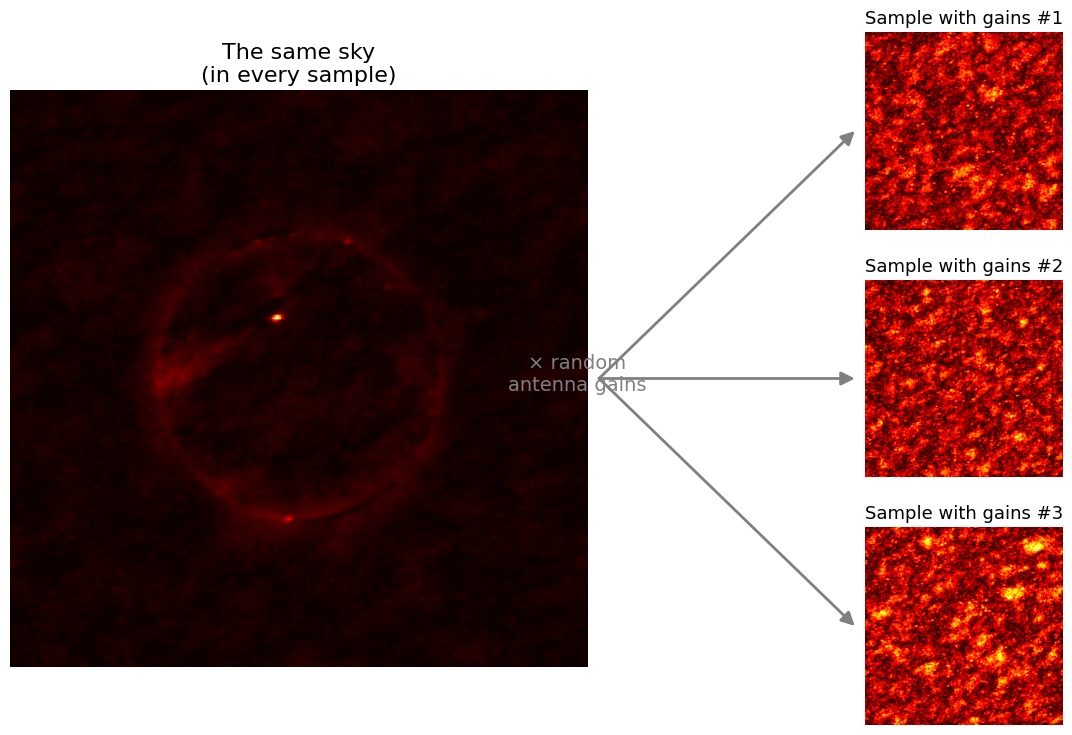

In [ ]:
from matplotlib.patches import ConnectionPatch

Xc = np.load("/content/drive/MyDrive/CS 163/cs163_calibrated/X_calibrated.npy", mmap_mode="r")

# baseline -> antenna index, using the same rows as u_all / v_all (autocorrelations removed)
cross = uvd.ant_1_array != uvd.ant_2_array
ants = np.union1d(uvd.ant_1_array, uvd.ant_2_array)
bi = np.searchsorted(ants, uvd.ant_1_array[cross])
bj = np.searchsorted(ants, uvd.ant_2_array[cross])

def to_image(M):
    """214x214 complex matrix -> sky image"""
    return np.abs(uncalibraed_image(u_all, v_all, M[bi, bj]))

def as_complex(T, k):
    return T[k, 0].astype(np.float32) + 1j * T[k, 1].astype(np.float32)

# the one shared sky = average of calibrated samples
sky = np.mean([as_complex(Xc, k) for k in range(20, 120)], axis=0)
samples = [20, 500, 3000]                      # any 3 samples

fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(3, 3, width_ratios=[2.2, 0.8, 1], wspace=0.05, hspace=0.25)

ax_sky = fig.add_subplot(gs[:, 0])
ax_sky.imshow(to_image(sky), cmap="hot", origin="lower")
ax_sky.set_title("The same sky\n(in every sample)", fontsize=16)
ax_sky.axis("off")

for r, k in enumerate(samples):
    a = fig.add_subplot(gs[r, 2])
    a.imshow(to_image(as_complex(X, k)), cmap="hot", origin="lower")
    a.set_title(f"Sample with gains #{r + 1}", fontsize=13)
    a.axis("off")
    # arrow from the sky to this panel
    fig.add_artist(ConnectionPatch(xyA=(1.02, 0.5), coordsA=ax_sky.transAxes,
                                   xyB=(-0.05, 0.5), coordsB=a.transAxes,
                                   arrowstyle="-|>", lw=2, color="gray",
                                   mutation_scale=20))

fig.text(0.53, 0.5, "× random\nantenna gains", ha="center", va="center", fontsize=14, color="gray")
# plt.savefig("same_sky_different_gains.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
scores

[np.float32(0.9999997),
 np.float32(0.9999998),
 np.float32(0.9999999),
 np.float32(1.0),
 np.float32(0.9999998),
 np.float32(0.9999998),
 np.float32(0.9999998),
 np.float32(0.9999998),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999997),
 np.float32(1.0000001),
 np.float32(0.9999999),
 np.float32(1.0),
 np.float32(0.9999999),
 np.float32(0.9999998),
 np.float32(1.0),
 np.float32(0.9999998),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(1.0000001),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.99999976),
 np.float32(0.9999998),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999997),
 np.float32(1.0),
 np.float32(0.9999999),
 np.float32(1.0),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(0.9999997),
 np.float32(0.9999999),
 np.float32(0.9999999),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.9999997),
 np.float32(0.9999999),
 np.float

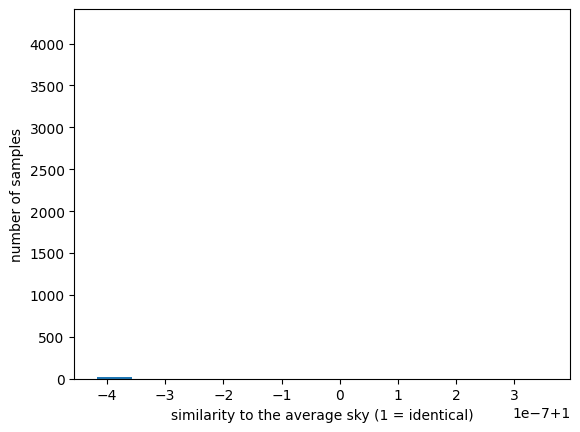

In [ ]:
scores = []
for s in range(0, len(Xc), 250):
    C = Xc[s:s + 250]
    V = C[:, 0].astype(np.float32) + 1j * C[:, 1].astype(np.float32)
    scores += list(similarity(V, sky))

plt.hist(scores, bins=50)
plt.xlabel("similarity to the average sky (1 = identical)"); plt.ylabel("number of samples")
plt.show()

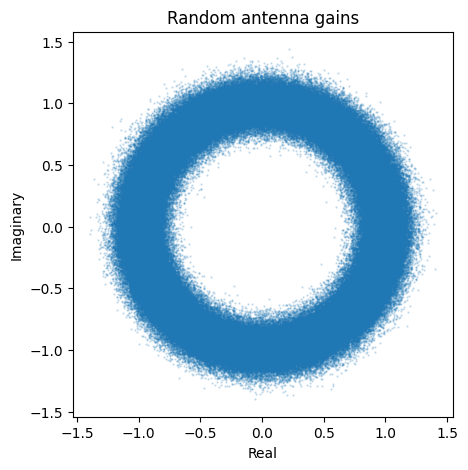

In [ ]:
g = (Y[:2000, 0] + 1j * Y[:2000, 1]).ravel()
plt.figure(figsize=(5, 5))
plt.scatter(g.real, g.imag, s=0.5, alpha=0.2)
plt.gca().set_aspect("equal"); plt.xlabel("Real"); plt.ylabel("Imaginary")
plt.title("Random antenna gains")
plt.show()

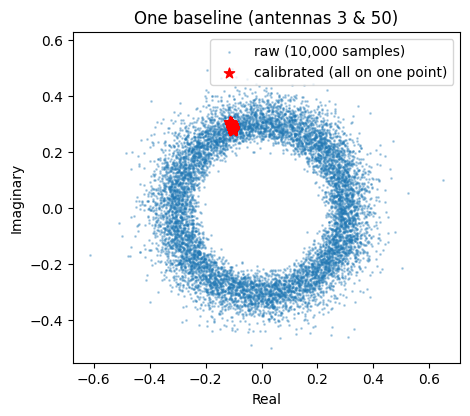

In [ ]:
i, j = 3, 50                                   # any antenna pair
raw = X[:, 0, i, j].astype(np.float32) + 1j * X[:, 1, i, j].astype(np.float32)
cal = Xc[:, 0, i, j].astype(np.float32) + 1j * Xc[:, 1, i, j].astype(np.float32)
plt.figure(figsize=(5, 5))
plt.scatter(raw.real, raw.imag, s=1, alpha=0.3, label="raw (10,000 samples)")
plt.scatter(cal.real, cal.imag, s=60, c="red", marker="*", label="calibrated (all on one point)")
plt.gca().set_aspect("equal"); plt.xlabel("Real"); plt.ylabel("Imaginary"); plt.legend()
plt.title(f"One baseline (antennas {i} & {j})")
plt.show()

## Video Generation

In [ ]:
# !sudo apt-get -qq update
# !sudo apt-get -qq install -y libcairo2-dev libpango1.0-dev ffmpeg
# !pip install -q manim

In [ ]:
# %%writefile interferometer.py
# from manim import *
# import numpy as np

# BG = "#0b0f19"
# config.background_color = BG

# class Interferometer(Scene):
#     def construct(self):
#         GY = -1.2              # ground level
#         XL, XR = -3.0, 3.0     # antenna x-positions
#         DISH_Y = GY + 1.1      # dish aperture height
#         LAM = 0.9              # wavelength (scene units)
#         B = XR - XL            # baseline length
#         pL = np.array([XL, DISH_Y, 0.0])
#         pR = np.array([XR, DISH_Y, 0.0])

#         theta = ValueTracker(35 * DEGREES)   # source angle from zenith
#         phase = ValueTracker(0.0)            # how far the waves have travelled

#         def s_hat():   # unit vector toward source
#             th = theta.get_value()
#             return np.array([np.sin(th), np.cos(th), 0.0])

#         def d_hat():   # direction along a wavefront
#             th = theta.get_value()
#             return np.array([np.cos(th), -np.sin(th), 0.0])

#         # ---------------- plane wavefronts ----------------
#         def make_waves():
#             s, d, ph = s_hat(), d_hat(), phase.get_value()
#             g = VGroup()
#             for k in range(int(np.floor((-8 + ph) / LAM)), int(np.ceil((10 + ph) / LAM)) + 1):
#                 ctr = (k * LAM - ph) * s
#                 g.add(Line(ctr - 10 * d, ctr + 10 * d, stroke_width=2.5,
#                            color=BLUE_C, stroke_opacity=0.75))
#             return g
#         waves = always_redraw(make_waves)

#         # ---------------- ground ----------------
#         ground_mask = Rectangle(width=16, height=6, fill_color=BG, fill_opacity=1,
#                                 stroke_width=0).move_to([0, GY - 3, 0]).set_z_index(5)
#         ground = Line([-7.5, GY, 0], [7.5, GY, 0], color=GREY_B, stroke_width=3).set_z_index(6)

#         # ---------------- dishes (light up when a wavefront hits) ----------------
#         def glow(p):
#             x = (np.dot(p, s_hat()) + phase.get_value()) % LAM
#             return float(np.exp(-(min(x, LAM - x) / 0.12) ** 2))

#         def make_dish(p, name, side):
#             bowl = Arc(radius=0.55, start_angle=PI, angle=PI, arc_center=p,
#                        stroke_width=6, color=GREY_A)
#             stand = Line(p + 0.55 * DOWN, [p[0], GY, 0], stroke_width=4, color=GREY_B)
#             feed = Line(p + 0.55 * DOWN, p + 0.25 * UP, stroke_width=2, color=GREY_B)
#             label = Text(name, font_size=22, color=GREY_A).next_to(stand, side, buff=0.15)
#             bowl.add_updater(lambda m: m.set_stroke(
#                 color=interpolate_color(GREY_A, YELLOW, glow(p)), width=6 + 4 * glow(p)))
#             return VGroup(stand, feed, bowl, label).set_z_index(7)

#         dish1 = make_dish(pL, "Antenna 1", LEFT)
#         dish2 = make_dish(pR, "Antenna 2", RIGHT)

#         # ---------------- source + direction ----------------
#         src = always_redraw(lambda: Star(n=5, outer_radius=0.22, inner_radius=0.09,
#                                          color=YELLOW, fill_opacity=1)
#                             .move_to(np.array([0, DISH_Y, 0]) + 4.0 * s_hat()).set_z_index(9))
#         src_lbl = Text("distant source", font_size=22, color=YELLOW).next_to(
#             np.array([0, DISH_Y, 0]) + 4.0 * s_hat(), RIGHT, buff=0.35)

#         def make_s_arrow():
#             o = np.array([0, DISH_Y, 0])
#             a = Arrow(o, o + 1.4 * s_hat(), buff=0, color=YELLOW_B, stroke_width=4,
#                       max_tip_length_to_length_ratio=0.2)
#             lbl = Text("ŝ", font_size=28, color=YELLOW_B).next_to(a.get_end(), RIGHT, buff=0.1)
#             return VGroup(a, lbl).set_z_index(7)
#         s_arrow = always_redraw(make_s_arrow)

#         baseline = DoubleArrow([XL, GY - 0.35, 0], [XR, GY - 0.35, 0], buff=0,
#                                color=GREY_A, tip_length=0.2).set_z_index(8)
#         b_lbl = Text("baseline b", font_size=22, color=GREY_A).next_to(baseline, DOWN, buff=0.1).set_z_index(8)

#         title = Text("Two-element radio interferometer", font_size=32,
#                      weight=BOLD).to_corner(UL).set_z_index(9)

#         # ================= ACT 1: waves sweep in =================
#         self.add(ground_mask)
#         self.play(Write(title), Create(ground), FadeIn(dish1), FadeIn(dish2), run_time=1.5)
#         self.play(FadeIn(src), FadeIn(src_lbl), FadeIn(s_arrow))
#         self.play(GrowFromCenter(baseline), Write(b_lbl))
#         self.add(waves)
#         self.play(phase.animate.increment_value(8 * LAM), run_time=6, rate_func=linear)

#         # ================= ACT 2: geometric delay =================
#         s, d = s_hat(), d_hat()
#         foot = pL + B * np.sin(theta.get_value()) * s
#         wf = DashedLine(pR - 8 * d, pR + 3 * d, color=WHITE, stroke_width=2).set_z_index(4)
#         delay = Line(pL, foot, color=YELLOW, stroke_width=7).set_z_index(8)
#         ra = RightAngle(Line(foot, pL), Line(foot, pR), length=0.22, color=WHITE).set_z_index(8)
#         delay_lbl = VGroup(Text("extra path", font_size=24, color=YELLOW),
#                            Text("cτ = b · sin θ", font_size=28, color=YELLOW)
#                            ).arrange(DOWN, aligned_edge=LEFT, buff=0.1)
#         delay_lbl.add_background_rectangle(opacity=0.85)
#         delay_lbl.next_to(delay, LEFT, buff=0.15).set_z_index(9)

#         self.play(Create(wf), run_time=1)
#         self.play(Create(delay), Create(ra), run_time=1.2)
#         self.play(FadeIn(delay_lbl, shift=0.2 * RIGHT))
#         self.wait(2.5)
#         self.play(*[FadeOut(m) for m in [wf, delay, ra, delay_lbl, baseline, b_lbl, src_lbl, title]])

#         # ================= ACT 3: correlator + fringes =================
#         box = RoundedRectangle(corner_radius=0.15, width=2.4, height=1.0, color=TEAL,
#                                fill_color=BG, fill_opacity=1).move_to([-2.2, -2.75, 0])
#         box_txt = VGroup(Text("Correlator", font_size=26),
#                          Text("multiply & average", font_size=18, color=GREY_A)
#                          ).arrange(DOWN, buff=0.08).move_to(box)
#         top = box.get_top()[1]
#         wire1 = VMobject(color=GREY_B, stroke_width=3).set_points_as_corners(
#             [[XL, GY, 0], [XL, top, 0]])
#         wire2 = VMobject(color=GREY_B, stroke_width=3).set_points_as_corners(
#             [[XR, GY, 0], [XR, -1.65, 0], [-1.6, -1.65, 0], [-1.6, top, 0]])
#         corr = VGroup(wire1, wire2, box, box_txt).set_z_index(8)

#         self.play(Create(wire1), Create(wire2), FadeIn(box), Write(box_txt),
#                   phase.animate.increment_value(2 * LAM), run_time=1.5, rate_func=linear)
#         dot1 = Dot(color=YELLOW).set_z_index(9)
#         dot2 = Dot(color=YELLOW).set_z_index(9)
#         self.play(MoveAlongPath(dot1, wire1), MoveAlongPath(dot2, wire2),
#                   phase.animate.increment_value(2 * LAM), run_time=1.5, rate_func=linear)
#         self.remove(dot1, dot2)

#         # fringe plot: correlator output as the source drifts across the sky
#         axes = Axes(x_range=[0, 70, 10], y_range=[-1.2, 1.2, 1], x_length=4.6, y_length=1.4,
#                     tips=False, axis_config={"color": GREY_B, "stroke_width": 2}
#                     ).move_to([3.4, -2.85, 0]).set_z_index(8)
#         ax_title = Text("correlator output", font_size=20).next_to(axes, UP, buff=0.12).set_z_index(8)
#         ax_x = Text("time  (source drifts across sky) →", font_size=16, color=GREY_A
#                     ).next_to(axes, DOWN, buff=0.1).set_z_index(8)
#         out_arrow = Arrow(box.get_right(), axes.get_left(), buff=0.15, color=TEAL,
#                           stroke_width=3).set_z_index(8)

#         fringe = lambda x: np.cos(2 * np.pi * B * np.sin((35 - x) * DEGREES) / LAM)
#         cur_x = lambda: 35 - theta.get_value() / DEGREES

#         def make_trace():
#             if cur_x() < 0.3:
#                 return VMobject()
#             return axes.plot(fringe, x_range=[0, cur_x(), 0.2], color=YELLOW,
#                              stroke_width=3).set_z_index(9)
#         trace = always_redraw(make_trace)
#         tracer = always_redraw(lambda: Dot(axes.c2p(cur_x(), fringe(cur_x())),
#                                            color=YELLOW, radius=0.06).set_z_index(10))

#         self.play(GrowArrow(out_arrow), Create(axes), Write(ax_title), Write(ax_x), run_time=1.2)
#         self.add(trace, tracer)
#         self.play(theta.animate.set_value(-35 * DEGREES),
#                   phase.animate.increment_value(14 * LAM), run_time=9, rate_func=linear)

#         caption = Text("Fringe phase encodes where the source is", font_size=26
#                        ).to_corner(UR).set_z_index(9)
#         caption.add_background_rectangle(opacity=0.85)
#         self.play(FadeIn(caption, shift=0.2 * DOWN))
#         self.wait(2)

In [ ]:
# !manim -qh interferometer.py Interferometer

# from IPython.display import Video
# from google.colab import files
# path = "media/videos/interferometer/1080p60/Interferometer.mp4"
# display(Video(path, embed=True, width=800))
# files.download(path)

In [ ]:
# !sudo apt-get -qq update
# !sudo apt-get -qq install -y libcairo2-dev libpango1.0-dev ffmpeg texlive texlive-latex-extra texlive-fonts-recommended cm-super dvisvgm > /dev/null
# !pip install -q manim

In [ ]:
# %%writefile interferometer.py
# from manim import *
# import numpy as np

# BG, WAVE, GOLD, TEAL, INK, DIM = "#0b0f19", "#5DA9E9", "#F2C14E", "#4FD1C5", "#E8E6E3", "#8A93A6"
# config.background_color = BG

# class Interferometer(MovingCameraScene):
#     def construct(self):
#         frame = self.camera.frame
#         GY, XL, XR = -1.2, -3.0, 3.0
#         DISH_Y = GY + 1.1
#         LAM, R = 0.9, 16.0                     # wavelength, source distance
#         O  = np.array([0, DISH_Y, 0.0])
#         pL = np.array([XL, DISH_Y, 0.0]); pR = np.array([XR, DISH_Y, 0.0])
#         TH0 = 30 * DEGREES
#         theta = ValueTracker(TH0)              # source angle from zenith
#         phase = ValueTracker(0.0)              # radius of the first emitted wavefront

#         def s_hat(th=None):
#             th = theta.get_value() if th is None else th
#             return np.array([np.sin(th), np.cos(th), 0.0])
#         def src_pos(th=None): return O + R * s_hat(th)
#         def dist(p, th=None): return np.linalg.norm(p - src_pos(th))
#         def wave_arg(p): return (phase.get_value() - dist(p)) / LAM   # cycles

#         def glow(p):
#             a = wave_arg(p)
#             if a < 0: return 0.0
#             w = a % 1
#             return float(np.exp(-((min(w, 1 - w) * LAM) / 0.12) ** 2))

#         def V(p, u):                            # antenna voltage, u cycles in the past
#             a = wave_arg(p) - u
#             return np.cos(2 * np.pi * a) if a > 0 else 0.0

#         def mean_at(th):                        # time-averaged correlator output
#             return 0.5 * np.cos(2 * np.pi * (dist(pL, th) - dist(pR, th)) / LAM)

#         def cap(tex, size=32):
#             t = Tex(tex, font_size=size, color=INK)
#             t.add_background_rectangle(color=BG, opacity=0.85, buff=0.15)
#             return t.set_z_index(10)

#         # ---------- spherical wavefronts emitted by the source ----------
#         def make_rings():
#             ph, c, g, k = phase.get_value(), src_pos(), VGroup(), 0
#             while True:
#                 r = ph - k * LAM
#                 if r <= 0.02: break
#                 if r < 30:
#                     g.add(Circle(radius=r, arc_center=c, stroke_color=WAVE, stroke_width=2.5,
#                                  stroke_opacity=0.85 * min(1, r / 1.5)))
#                 k += 1
#             return g
#         rings = always_redraw(make_rings)

#         mask = Rectangle(width=200, height=100, fill_color=BG, fill_opacity=1,
#                          stroke_width=0).move_to([0, GY - 50, 0]).set_z_index(5)
#         ground = Line([-60, GY, 0], [60, GY, 0], color=DIM, stroke_width=3).set_z_index(6)

#         def make_dish(p, name, side):
#             bowl = Arc(radius=0.6, start_angle=PI, angle=PI, arc_center=p, stroke_width=6, color=INK)
#             legs = VGroup(Line(p + 0.6 * LEFT, p + 0.45 * UP), Line(p + 0.6 * RIGHT, p + 0.45 * UP)).set_stroke(DIM, 1.5)
#             feed = Dot(p + 0.45 * UP, radius=0.05, color=INK)
#             stand = Line(p + 0.6 * DOWN, [p[0], GY, 0], stroke_width=4, color=DIM)
#             label = Tex(name, font_size=30, color=INK).next_to(stand, side, buff=0.2)
#             bowl.add_updater(lambda m: m.set_stroke(
#                 color=interpolate_color(ManimColor(INK), ManimColor(GOLD), glow(p)), width=6 + 5 * glow(p)))
#             return VGroup(stand, legs, bowl, feed, label).set_z_index(7)
#         dish1, dish2 = make_dish(pL, "Antenna 1", LEFT), make_dish(pR, "Antenna 2", RIGHT)

#         src_star = always_redraw(lambda: VGroup(
#             Dot(src_pos(), radius=0.9, color=GOLD, fill_opacity=0.15),
#             Dot(src_pos(), radius=0.5, color=GOLD, fill_opacity=0.3),
#             Star(n=5, outer_radius=0.42, inner_radius=0.18, color=GOLD, fill_opacity=1).move_to(src_pos())
#         ).set_z_index(9))

#         def make_s_arrow():
#             a = Arrow(O, O + 1.6 * s_hat(), buff=0, color=GOLD, stroke_width=4, max_tip_length_to_length_ratio=0.18)
#             l = MathTex(r"\hat{\mathbf s}", color=GOLD).next_to(a.get_end(), RIGHT, buff=0.12)
#             return VGroup(a, l).set_z_index(7)
#         s_arrow = always_redraw(make_s_arrow)

#         baseline = DoubleArrow([XL, GY - 0.35, 0], [XR, GY - 0.35, 0], buff=0, color=DIM,
#                                tip_length=0.18, stroke_width=3).set_z_index(8)
#         b_lbl = MathTex(r"\mathbf b", color=INK).next_to(baseline, DOWN, buff=0.1).set_z_index(8)

#         # ================= ACT 1: source emits, zoom to array =================
#         K = 36 / 14.2
#         frame.set(width=36).move_to([5, 6.5, 0])
#         title = Tex(r"\textbf{Two-element radio interferometer}", font_size=44, color=INK).scale(K)
#         title.move_to(frame.get_corner(UL) + np.array([1.2, -1.2, 0]), aligned_edge=UL).set_z_index(10)
#         sub = Tex(r"a distant source radiates spherical wavefronts", font_size=32, color=DIM).scale(K)
#         sub.next_to(title, DOWN, aligned_edge=LEFT, buff=0.5).set_z_index(10)
#         src_lbl = Tex("radio source", font_size=32, color=GOLD).scale(K).next_to(src_pos(), RIGHT, buff=1.3).set_z_index(10)

#         self.add(mask, src_star)
#         self.play(Create(ground), FadeIn(dish1), FadeIn(dish2), Write(title), FadeIn(src_lbl), run_time=2)
#         self.add(rings)
#         self.play(FadeIn(sub), phase.animate.set_value(20), run_time=7, rate_func=linear)
#         self.play(FadeOut(title), FadeOut(sub), FadeOut(src_lbl),
#                   frame.animate(rate_func=smooth).set(width=14.2).move_to([0, 0.9, 0]),
#                   phase.animate(rate_func=linear).increment_value(5), run_time=3.5)

#         ff = cap(r"Far field ($R \gg |\mathbf b|$): wavefronts arrive almost planar").move_to([0, 4.35, 0])
#         self.add(s_arrow)
#         self.play(FadeIn(ff), GrowFromCenter(baseline), Write(b_lbl),
#                   phase.animate.increment_value(5), run_time=4, rate_func=linear)

#         # ================= ACT 2: rays + geometric delay =================
#         src, dLv, dRv = src_pos(), dist(pL), dist(pR)
#         u = (src - pL) / dLv
#         foot = pL + (dLv - dRv) * u
#         a0 = np.arctan2(pR[1] - src[1], pR[0] - src[0])
#         rays = VGroup(DashedLine(pL, pL + 7 * u), DashedLine(pR, pR + 7 * (src - pR) / dRv)).set_stroke(DIM, 2).set_z_index(6)
#         wf = DashedVMobject(Arc(radius=dRv, start_angle=a0 - 0.45, angle=0.65, arc_center=src),
#                             num_dashes=45).set_stroke(INK, 2).set_z_index(6)
#         zen = DashedLine(pL, pL + 2.2 * UP).set_stroke(DIM, 1.5).set_z_index(6)
#         ang = Angle(Line(pL, pL + u), Line(pL, pL + UP), radius=0.8, color=INK).set_z_index(8)
#         th_lbl = MathTex(r"\theta", color=INK).move_to(
#             Angle(Line(pL, pL + u), Line(pL, pL + UP), radius=1.15).point_from_proportion(0.5)).set_z_index(8)
#         delay = Line(pL, foot, color=GOLD, stroke_width=7).set_z_index(8)
#         d_lbl = VGroup(MathTex(r"c\,\tau_g = |\mathbf b|\sin\theta", font_size=40, color=GOLD),
#                        Tex("extra path to Antenna 1", font_size=26, color=DIM)).arrange(DOWN, buff=0.12)
#         d_lbl.add_background_rectangle(color=BG, opacity=0.85, buff=0.12)
#         d_lbl.move_to([-4.9, 3.1, 0]).set_z_index(10)
#         ptr = Arrow(d_lbl.get_bottom(), delay.get_center(), buff=0.12, color=GOLD, stroke_width=3,
#                     max_tip_length_to_length_ratio=0.12).set_z_index(9)

#         self.play(Create(rays), run_time=1.2)
#         self.play(Create(wf), run_time=1.2)
#         self.play(Create(zen), Create(ang), Write(th_lbl), run_time=1)
#         self.play(Create(delay), run_time=1.2)
#         self.play(FadeIn(d_lbl), GrowArrow(ptr))
#         self.wait(3)

#         # ================= ACT 3: correlator, step by step =================
#         s_arrow.clear_updaters()
#         self.play(*[FadeOut(m) for m in [rays, wf, zen, ang, th_lbl, delay, d_lbl, ptr, ff, baseline, b_lbl, s_arrow]],
#                   frame.animate(rate_func=smooth).set(width=18).move_to([0, -3.4, 0]),
#                   phase.animate(rate_func=linear).increment_value(2.5 * LAM), run_time=2.5)

#         def scope(cx, cy, xl=3.6, yl=0.9, yr=1.2):
#             return Axes(x_range=[0, 3, 1], y_range=[-yr, yr, 1], x_length=xl, y_length=yl, tips=False,
#                         axis_config={"stroke_color": DIM, "stroke_width": 1.5, "include_ticks": False}
#                         ).move_to([cx, cy, 0]).set_z_index(8)
#         ax1, ax2 = scope(-3.2, -2.55), scope(3.2, -2.55)
#         w1 = Line([XL, GY, 0], [XL, ax1.get_top()[1], 0], color=DIM, stroke_width=2).set_z_index(8)
#         w2 = Line([XR, GY, 0], [XR, ax2.get_top()[1], 0], color=DIM, stroke_width=2).set_z_index(8)
#         v1l = MathTex(r"V_1(t)", color=WAVE).next_to(ax1, LEFT, buff=0.25).set_z_index(8)
#         v2l = MathTex(r"V_2(t)", color=TEAL).next_to(ax2, RIGHT, buff=0.25).set_z_index(8)
#         tr1 = always_redraw(lambda: ax1.plot(lambda x: V(pL, 3 - x), x_range=[0, 3, 0.02], color=WAVE, stroke_width=3).set_z_index(9))
#         tr2 = always_redraw(lambda: ax2.plot(lambda x: V(pR, 3 - x), x_range=[0, 3, 0.02], color=TEAL, stroke_width=3).set_z_index(9))
#         dphi = MathTex(r"\Delta\phi = 2\pi\nu\,\tau_g", font_size=34, color=INK).move_to([0, -2.55, 0]).set_z_index(8)

#         c1 = cap(r"Each antenna records a voltage; Antenna 1 lags by $\tau_g$").move_to([0, 1.15, 0])
#         self.play(Create(w1), Create(w2), Create(ax1), Create(ax2), Write(v1l), Write(v2l), FadeIn(c1),
#                   phase.animate.increment_value(1.5 * LAM), run_time=1.5, rate_func=linear)
#         self.add(tr1, tr2)
#         self.play(Write(dphi), phase.animate.increment_value(2.5 * LAM), run_time=2.5, rate_func=linear)

#         mult = VGroup(Circle(radius=0.32, color=INK, stroke_width=2.5), MathTex(r"\times", color=INK)).move_to([0, -3.85, 0]).set_z_index(8)
#         pax = scope(0, -5.15, xl=5.6, yl=1.2, yr=1.1)
#         m1 = VMobject(stroke_color=DIM, stroke_width=2).set_points_as_corners(
#             [ax1.get_bottom(), [ax1.get_bottom()[0], -3.85, 0], [-0.32, -3.85, 0]]).set_z_index(8)
#         m2 = VMobject(stroke_color=DIM, stroke_width=2).set_points_as_corners(
#             [ax2.get_bottom(), [ax2.get_bottom()[0], -3.85, 0], [0.32, -3.85, 0]]).set_z_index(8)
#         m3 = Line([0, -4.17, 0], pax.get_top(), color=DIM, stroke_width=2).set_z_index(8)
#         pl = MathTex(r"V_1V_2", color=INK).next_to(pax, LEFT, buff=0.25).set_z_index(8)
#         ptr_ = always_redraw(lambda: pax.plot(lambda x: V(pL, 3 - x) * V(pR, 3 - x), x_range=[0, 3, 0.02],
#                                               color=INK, stroke_width=2.5, stroke_opacity=0.75).set_z_index(9))
#         mean_line = always_redraw(lambda: DashedLine(pax.c2p(0, mean_at(theta.get_value())),
#                                                      pax.c2p(3, mean_at(theta.get_value())),
#                                                      color=GOLD, stroke_width=5).set_z_index(10))
#         mean_lbl = always_redraw(lambda: MathTex(r"\langle V_1V_2\rangle", color=GOLD)
#                                  .next_to(pax.c2p(3, mean_at(theta.get_value())), RIGHT, buff=0.2).set_z_index(10))

#         c2 = cap(r"Correlator: multiply the signals, then time-average (dashed line)").move_to([0, 1.15, 0])
#         self.play(Create(m1), Create(m2), FadeIn(mult), Create(m3), Create(pax), Write(pl), FadeOut(c1), FadeIn(c2),
#                   phase.animate.increment_value(2 * LAM), run_time=2, rate_func=linear)
#         self.add(ptr_, mean_line, mean_lbl)
#         self.play(phase.animate.increment_value(3.5 * LAM), run_time=3.5, rate_func=linear)

#         fax = Axes(x_range=[0, 1, 0.25], y_range=[-0.6, 0.6, 0.5], x_length=9, y_length=1.4, tips=False,
#                    axis_config={"stroke_color": DIM, "stroke_width": 1.5, "include_ticks": False}
#                    ).move_to([0, -7.2, 0]).set_z_index(8)
#         f_title = Tex(r"Correlator output $\langle V_1V_2\rangle$ over time", font_size=30, color=INK).next_to(fax, UP, buff=0.12).set_z_index(8)
#         f_x = Tex(r"time $\rightarrow$ \;(Earth rotates, so $\theta$ and $\tau_g$ change)", font_size=24, color=DIM).next_to(fax, DOWN, buff=0.12).set_z_index(8)
#         cur = lambda: (TH0 - theta.get_value()) / (2 * TH0)
#         fr = lambda x: mean_at(TH0 - 2 * TH0 * x)
#         trace = always_redraw(lambda: fax.plot(fr, x_range=[0, max(cur(), 0.003), 0.002], color=GOLD, stroke_width=3.5).set_z_index(9))
#         tracer = always_redraw(lambda: Dot(fax.c2p(cur(), fr(cur())), color=GOLD, radius=0.07).set_z_index(10))

#         c3 = cap(r"As the Earth rotates, $\theta$ drifts, so the average oscillates: \emph{fringes}").move_to([0, 1.15, 0])
#         self.play(Create(fax), Write(f_title), Write(f_x), FadeOut(c2), FadeIn(c3),
#                   phase.animate.increment_value(1.5 * LAM), run_time=1.5, rate_func=linear)
#         self.add(trace, tracer)
#         self.play(theta.animate.set_value(-TH0), phase.animate.increment_value(14 * LAM), run_time=13, rate_func=linear)

#         eq = MathTex(r"\langle V_1V_2\rangle \;=\; \tfrac{1}{2}\cos\!\left(\frac{2\pi\,|\mathbf b|\sin\theta}{\lambda}\right)",
#                      font_size=42, color=INK)
#         eq.add_background_rectangle(color=BG, opacity=0.85, buff=0.15)
#         eq.move_to([0, 1.05, 0]).set_z_index(10)
#         self.play(FadeOut(c3), FadeIn(eq), phase.animate.increment_value(1.5 * LAM), run_time=1.5, rate_func=linear)
#         self.play(phase.animate.increment_value(3 * LAM), run_time=3, rate_func=linear)

In [ ]:
# !manim -qh interferometer.py Interferometer

# from IPython.display import Video
# from google.colab import files
# path = "media/videos/interferometer/1080p60/Interferometer.mp4"
# display(Video(path, embed=True, width=900))
# files.download(path)